# 01 — Phase 1: Tiền xử lý + outlier

Phase 1 — Tiền xử lý + gắn cờ outlier (`scripts/preprocess.py`).

Không xóa outlier, chỉ gắn cờ: cờ IQR trên tỉ số công suất/bức xạ ban ngày, cờ bức xạ cao/công suất thấp, và z-score. Nhiệt độ phi lý (môi trường > 80 °C, module > 100 °C) chuyển thành thiếu.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thư mục gốc của repo (notebook nằm trong notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Repo root:", ROOT)
print("Python:", sys.executable)

Repo root: /home/hatch/workspace/data-mining-project/repo
Python: /home/hatch/workspace/data-mining-project/.venv/bin/python


In [2]:
# Chạy script tương ứng (dùng đúng Python của kernel này)
import subprocess
r = subprocess.run([sys.executable, str(ROOT / "scripts" / "preprocess.py")],
                   capture_output=True, text=True)
print(r.stdout[-3000:])
print(r.stderr[-1000:] if r.returncode else "OK, exit 0")
assert r.returncode == 0, "script chạy lỗi, xem stderr ở trên"

System 4: 8760 giờ, thiếu 0 giờ, ban ngày 3736 giờ, outlier 537 giờ (14.37%), trong đó bức xạ cao/công suất thấp: 28
System 1278: 8760 giờ, thiếu 0 giờ, ban ngày 4001 giờ, outlier 405 giờ (10.12%), trong đó bức xạ cao/công suất thấp: 0
System 1403: 8730 giờ, thiếu 30 giờ, ban ngày 3818 giờ, outlier 405 giờ (10.61%), trong đó bức xạ cao/công suất thấp: 8
Report: outputs/preprocess_report.json

OK, exit 0


## 1. Báo cáo tiền xử lý

In [3]:
import json
rep = json.load(open(ROOT / "outputs/preprocess_report.json"))
for r in rep:
    print(f"System {r['system_id']}: {r['input_rows']} giờ, "
          f"{r['daytime_hours']} giờ ban ngày, outlier IQR "
          f"{r['outlier_iqr_daytime']} giờ "
          f"({100 * r['outlier_iqr_daytime'] / r['daytime_hours']:.1f}%), "
          f"bức xạ cao/công suất thấp: {r['outlier_low_power_high_irr']} giờ")

System 4: 8760 giờ, 3736 giờ ban ngày, outlier IQR 537 giờ (14.4%), bức xạ cao/công suất thấp: 28 giờ
System 1278: 8760 giờ, 4001 giờ ban ngày, outlier IQR 405 giờ (10.1%), bức xạ cao/công suất thấp: 0 giờ
System 1403: 8730 giờ, 3818 giờ ban ngày, outlier IQR 405 giờ (10.6%), bức xạ cao/công suất thấp: 8 giờ


## 2. Xem data đã làm sạch

In [4]:
df = pd.read_csv(ROOT / "data/processed/system_4_2015_hourly_clean.csv",
                   parse_dates=["timestamp"])
print("Cột mới so với bản hourly:", [c for c in df.columns if c not in
      ["timestamp", "ac_power_w", "dc_power_w", "poa_irradiance_wm2",
       "ambient_temp_c", "module_temp_c", "n_samples"]])
df.head(3)

Cột mới so với bản hourly: ['is_daytime', 'power_per_kw', 'irr_ratio', 'outlier_iqr', 'outlier_low_power_high_irr', 'power_per_kw_z', 'poa_irradiance_wm2_z', 'ambient_temp_c_z', 'module_temp_c_z', 'outlier_any']


,timestamp,ac_power_w,dc_power_w,poa_irradiance_wm2,ambient_temp_c,module_temp_c,n_samples,is_daytime,power_per_kw,irr_ratio,outlier_iqr,outlier_low_power_high_irr,power_per_kw_z,poa_irradiance_wm2_z,ambient_temp_c_z,module_temp_c_z,outlier_any
0,2015-01-01 00:00:00,2.663140,0.0,0.0,-10.412610,-12.773267,60,False,2.663140,NaN,False,False,NaN,NaN,NaN,NaN,False
1,2015-01-01 01:00:00,2.661761,0.0,0.0,-10.261485,-12.573126,60,False,2.661761,NaN,False,False,NaN,NaN,NaN,NaN,False
2,2015-01-01 02:00:00,2.670981,0.0,0.0,-10.413063,-12.600923,60,False,2.670981,NaN,False,False,NaN,NaN,NaN,NaN,False


## 3. Vẽ: công suất theo bức xạ, tô đỏ giờ outlier (System 4)

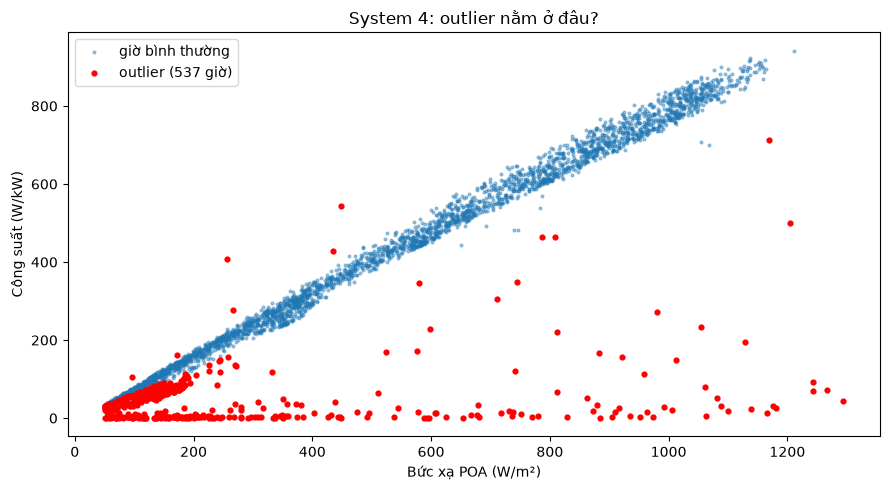

In [5]:
day = df[df["is_daytime"]]
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(day["poa_irradiance_wm2"], day["power_per_kw"], s=4, alpha=0.4,
           label="giờ bình thường")
out = day[day["outlier_any"]]
ax.scatter(out["poa_irradiance_wm2"], out["power_per_kw"], s=12, c="red",
           label=f"outlier ({len(out)} giờ)")
ax.set_xlabel("Bức xạ POA (W/m²)"); ax.set_ylabel("Công suất (W/kW)")
ax.set_title("System 4: outlier nằm ở đâu?")
ax.legend(); plt.tight_layout(); plt.show()